# The HF channel

What happens to a 188-110 signal between two radios, as Appendix E of MIL-STD-188-110C
models it, and as our time-varying extension stretches it. The walkthrough
(`walkthrough.ipynb`) follows one message through the modem; this notebook looks at the
channel itself, and at why the standard offers so many modes.

It is generated from `docs/channel.py` (`python tools/build_notebook.py channel`), and the
test suite runs that script. "INT-nnn" refers to `docs/SPEC_NOTES.md`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.animation import FuncAnimation
from nbtools import DOCS, QUICK, save_gif

from m110c.channel import schedule as sched
from m110c.channel.watterson import ChannelSpec, WattersonChannel

FS = 9600
plt.rcParams["figure.figsize"] = (8, 3)

## 1. The Watterson model (Appendix E)

Two copies of the signal arrive, a fixed *delay spread* apart (here 2 ms). Each is
multiplied by its own random complex gain: complex Gaussian noise passed through a
Gaussian filter, so its magnitude is Rayleigh-distributed and it changes at a rate set by
the *fading bandwidth* d (the Doppler spread, two sigma: INT-027). A fixed input of 1
through a one-path channel reads that gain out directly. On a 1-Hz channel the path fades
by 10-20 dB every second or two.

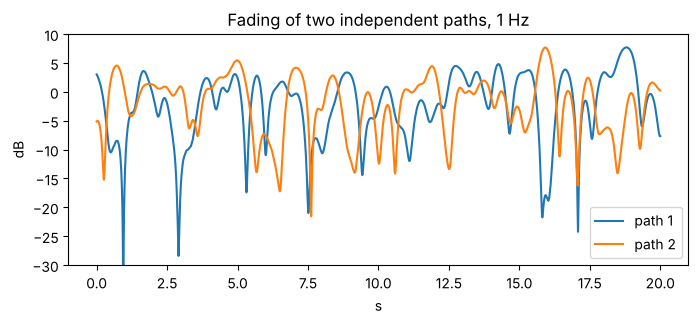

In [2]:
seconds = 10 if QUICK else 20
t = np.arange(seconds * FS) / FS
for seed, label in ((1, "path 1"), (2, "path 2")):
    gain = WattersonChannel(ChannelSpec(1, 0.0, 1.0), seed=seed).process(np.ones(t.size))
    plt.plot(t, 20 * np.log10(np.abs(gain) + 1e-9), label=label)
plt.ylim(-30, 10)
plt.xlabel("s")
plt.ylabel("dB")
plt.title("Fading of two independent paths, 1 Hz")
plt.legend()
plt.show()

The fading's power spectrum should be Appendix E's Gaussian, with standard deviation
d / 2 (E.5.4, INT-027). Averaging the spectrum of the gain over many seconds, it is:

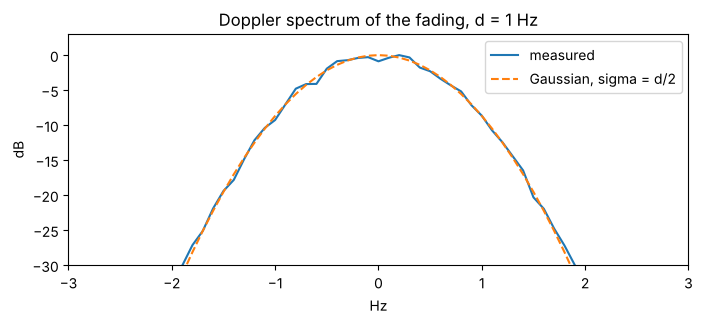

In [3]:
d = 1.0
seconds = 120 if QUICK else 600
gain = WattersonChannel(ChannelSpec(1, 0.0, d), seed=3).process(np.ones(seconds * FS))
rate = 100  # the fading is a few Hz wide: 100 samples per second is plenty
g = gain[:: FS // rate]
n_fft = 10 * rate  # 10-s segments: 0.1-Hz resolution
starts = range(0, g.size - n_fft + 1, n_fft // 2)  # half-overlapping
segments = np.stack([g[i : i + n_fft] for i in starts]) * np.hanning(n_fft)
psd = np.mean(np.abs(np.fft.fftshift(np.fft.fft(segments, axis=1), axes=1)) ** 2, axis=0)
f = np.fft.fftshift(np.fft.fftfreq(n_fft, 1 / rate))
theory = np.exp(-(f**2) / (2 * (d / 2) ** 2))
plt.plot(f, 10 * np.log10(psd / psd.max()), label="measured")
plt.plot(f, 10 * np.log10(theory + 1e-12), "--", label="Gaussian, sigma = d/2")
plt.xlim(-3, 3)
plt.ylim(-30, 3)
plt.xlabel("Hz")
plt.ylabel("dB")
plt.title(f"Doppler spectrum of the fading, d = {d:g} Hz")
plt.legend()
plt.show()

And the gain's magnitude is Rayleigh-distributed, as a sum of many scattered rays would be
(a complex Gaussian's magnitude): most of the time near its average, but with a long tail of
deep fades. About 1% of the time the path is more than 20 dB down.

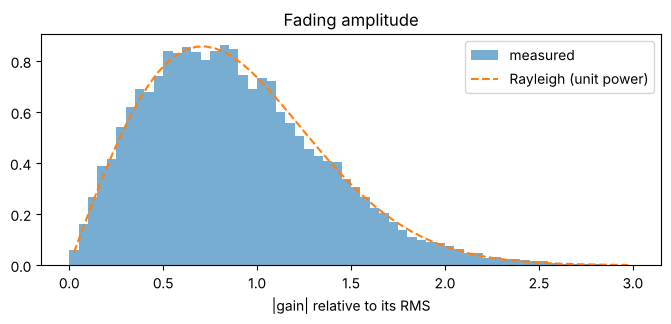

more than 20 dB down 1.10% of the time (Rayleigh: 1.00%)


In [4]:
r = np.abs(gain) / np.sqrt(np.mean(np.abs(gain) ** 2))
edges = np.linspace(0, 3, 61)
plt.hist(r, bins=edges, density=True, alpha=0.6, label="measured")
centres = (edges[1:] + edges[:-1]) / 2
plt.plot(centres, 2 * centres * np.exp(-(centres**2)), "--", label="Rayleigh (unit power)")
plt.xlabel("|gain| relative to its RMS")
plt.title("Fading amplitude")
plt.legend()
plt.show()
print(
    f"more than 20 dB down {np.mean(r < 0.1):.2%} of the time (Rayleigh: {1 - np.exp(-0.01):.2%})"
)

### The channel as it changes

The receiver sees the channel as an impulse response: two taps, 2 ms apart, each
rising and falling on its own. Here it is over ten seconds of a 1-Hz channel. The
equaliser's job (see the walkthrough) is to measure these two taps at every probe and
undo them.

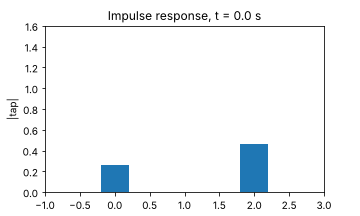

PosixPath('/home/user/MIL-STD-188-110/docs/figures/channel_impulse_response.gif')

In [5]:
spec = ChannelSpec(2, 2.0, 1.0)
L = int(round(spec.delay_ms * 1e-3 * FS))
frames = 40 if QUICK else 100
period = FS // 10  # an impulse every 0.1 s: read both taps from the output
x = np.zeros(frames * period, complex)
x[::period] = 1.0
y = WattersonChannel(spec, seed=4).process(x)
taps = np.stack([y[::period], y[L::period]], axis=1)  # direct, and 2 ms later

fig, ax = plt.subplots(figsize=(5, 3))
bars = ax.bar([0, spec.delay_ms], [0, 0], width=0.4)
ax.set_xlim(-1, 3)
ax.set_ylim(0, 1.6)
ax.set_xlabel("delay (ms)")
ax.set_ylabel("|tap|")
title = ax.set_title("")


def draw(k):
    for bar, h in zip(bars, np.abs(taps[k]), strict=True):
        bar.set_height(h)
    title.set_text(f"Impulse response, t = {k / 10:.1f} s")
    return [*bars, title]


save_gif(FuncAnimation(fig, draw, frames=frames), "channel_impulse_response", fps=10)

## 2. Conditions that change

Appendix E's channel is stationary: its SNR and paths stay put for the length of a test.
Real links drift over minutes to hours (absorption, the MUF, a path coming and going).
`m110c.channel.schedule` describes such drift as a value against time, through points: a
straight line, or a random walk pinned to each point (a Brownian bridge), and
`TimeVaryingChannel` follows it. With constant schedules it is the Appendix E channel,
sample for sample. This extension is ours, not the standard's.

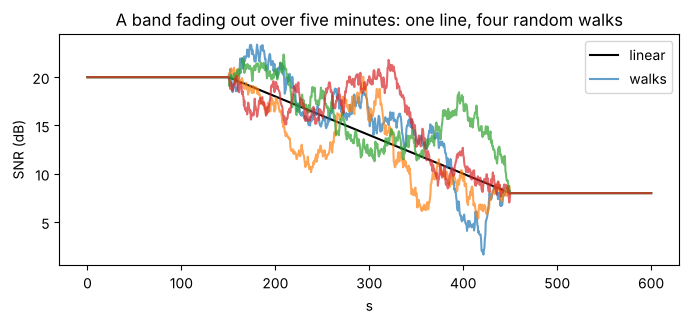

In [6]:
t = np.linspace(0, 600, 1201)
fig, ax = plt.subplots()
ax.plot(t, sched.linear(20, 8, duration_s=300, start_s=150).value(t), "k", label="linear")
for seed in range(4):
    walk = sched.walk(20, 8, duration_s=300, volatility=0.6, seed=seed, start_s=150)
    ax.plot(t, walk.value(t), alpha=0.7, label="walks" if seed == 0 else None)
ax.set_xlabel("s")
ax.set_ylabel("SNR (dB)")
ax.set_title("A band fading out over five minutes: one line, four random walks")
ax.legend()
plt.show()

## 3. What the standard asks for

Table XVI (§5.3.2.5) sets the bit error rate each rate must reach on given channels. From
`docs/CONFORMANCE.md` (generated by `tools/conformance.py`, up to a million bits per row):
every row meets its requirement. The faster the rate, the higher the SNR it is tested at.

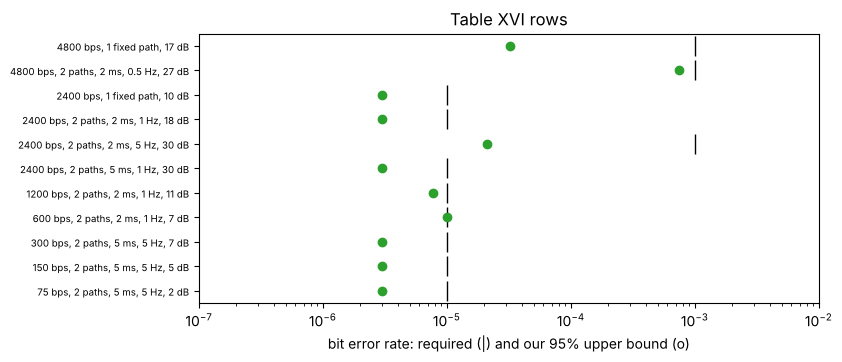

In [7]:
rows = []
for line in (DOCS / "CONFORMANCE.md").read_text().splitlines():
    cells = [c.strip() for c in line.strip("|").split("|")]
    if len(cells) == 11 and cells[0].isdigit():
        rows.append(cells)
fig, ax = plt.subplots(figsize=(8, 3.5))
for i, c in enumerate(rows):
    required, bound = float(c[3]), float(c[8])
    ax.plot([required], [i], "k|", markersize=14)
    ax.plot([bound], [i], "o", color="C2" if bound <= required else "C1")
ax.set_xscale("log")
ax.set_xlim(1e-7, 1e-2)
ax.set_yticks(range(len(rows)), [f"{c[0]} bps, {c[1]}, {c[2]}" for c in rows], fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("bit error rate: required (|) and our 95% upper bound (o)")
ax.set_title("Table XVI rows")
plt.show()

## 4. Matching the mode to the conditions

Why does the standard offer so many modes? Because no single one is best on every channel.
The figures below come from `tools/sweep.py`, which runs one-minute messages on many
channel realisations through the complete receiver, and saves its counts in
`docs/data/sweep.json` (hours to run, so the notebook only plots them). They are *this*
receiver's results, not limits of the standard: a different equaliser would move them.

A frame here is 256 bytes, delivered intact or lost; *goodput* is the rate times the
fraction of frames delivered: what a link layer would actually get.

In [8]:
import json  # noqa: E402

SWEEP = DOCS / "data" / "sweep.json"
points = json.loads(SWEEP.read_text())["points"] if SWEEP.exists() else {}
points = {k: p for k, p in points.items() if p.get("channels", 0) > 0}
if not points:
    print("No sweep data yet: run python tools/sweep.py")


def select(experiment, **match):
    out = [p for p in points.values() if p["experiment"] == experiment]
    return [p for p in out if all(p[k] == v for k, v in match.items())]


def ber(p):
    """Bit error rate; with no errors, half an error over the bits counted (a floor)."""
    return max(p["errors"], 0.5) / p["bits"]


def delivered(p):
    return p["frames_ok"] / p["frames"]

### Interleaving against fades

An interleaver spreads a fade's errors over its block (walkthrough, section 3), so it can
only help if the block is longer than a typical fade. A 0.5-Hz channel fades slowly, a
5-Hz one quickly; against them, the short interleaver's block is 0.6 s and the long one's
4.8 s:

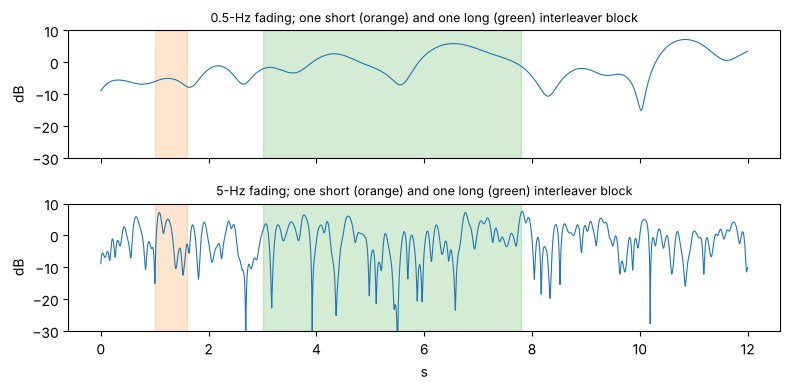

In [9]:
fig, ax = plt.subplots(2, 1, figsize=(8, 4), sharex=True)
for a, d_hz in zip(ax, (0.5, 5.0), strict=True):
    g = WattersonChannel(ChannelSpec(1, 0.0, d_hz), seed=12).process(np.ones(12 * FS))
    a.plot(np.arange(g.size) / FS, 20 * np.log10(np.abs(g) + 1e-9), lw=0.8)
    for start, length, colour in ((1.0, 0.6, "C1"), (3.0, 4.8, "C2")):
        a.axvspan(start, start + length, color=colour, alpha=0.2)
    a.set_ylim(-30, 10)
    a.set_ylabel("dB")
    a.set_title(
        f"{d_hz:g}-Hz fading; one short (orange) and one long (green) interleaver block", fontsize=9
    )
ax[1].set_xlabel("s")
plt.tight_layout()
plt.show()

Measured: 1200 bps at zero, short and long interleave, as the fraction of 256-byte frames
delivered intact. The long interleaver is clean from 10-12 dB at every fading speed. The
short one needs about 16 dB at 1 and 5 Hz, and about 20 dB on slow, 0.5-Hz fading, where a
fade lasts longer than its 0.6-s block. Without an interleaver, frames are still being lost
at 22 dB: every fade reaches the decoder whole.

Two dips at high SNR (short at 5 Hz, zero at 0.5 Hz) are whole one-minute messages lost,
not scattered errors, and they show two weaknesses of *this* receiver: a mode misread from
a faded preamble (1200S taken for 75S: D1 = 6 read as 7, and nothing cross-checked it
against the later segments), and a message abandoned for good after one long fade
("signal lost" with 59 s still to come). Both are recorded as receiver work in PLAN.md.

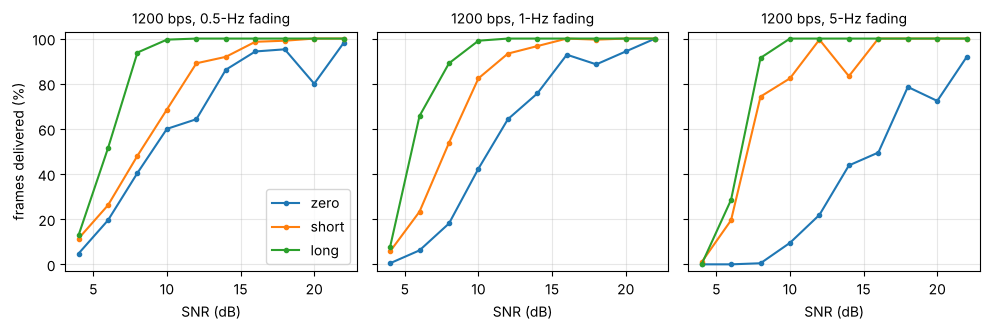

In [10]:
if points:
    fig, ax = plt.subplots(1, 3, figsize=(10, 3.4), sharey=True)
    for a, d_hz in zip(ax, (0.5, 1.0, 5.0), strict=True):
        for interleave in ("zero", "short", "long"):
            ps = sorted(
                select("interleave", doppler_hz=d_hz, interleave=interleave),
                key=lambda p: p["snr_db"],
            )
            if ps:
                a.plot(
                    [p["snr_db"] for p in ps],
                    [100 * delivered(p) for p in ps],
                    "o-",
                    markersize=3,
                    label=interleave,
                )
        a.set_title(f"1200 bps, {d_hz:g}-Hz fading", fontsize=10)
        a.set_xlabel("SNR (dB)")
        a.grid(True, alpha=0.3)
    ax[0].set_ylabel("frames delivered (%)")
    ax[0].set_ylim(-3, 103)
    if ax[0].get_legend_handles_labels()[0]:  # (a partial sweep may lack these points)
        ax[0].legend()
    plt.tight_layout()
    plt.show()

### Which rate, at which SNR

Each rate's goodput against SNR on Table XVI's commonest channel (2 paths, 2 ms, 1 Hz),
with the best of them at each SNR shaded. In this sweep: 75 bps is the only one that works
at 0 dB and below; 300 bps takes over at about 2 dB (150 bps is never quite the best: where
it works, 300 bps delivers nearly as reliably at twice the rate), 600 bps at about 4,
1200 bps from 6 to 10, and 2400 bps from 12. Uncoded 4800 bps never delivers every frame on
a fading channel, yet from about 22 dB the frames it does deliver beat 2400 bps's. The
crossovers are why a link should choose its rate from the conditions, as the playground's
negotiated transfer does.

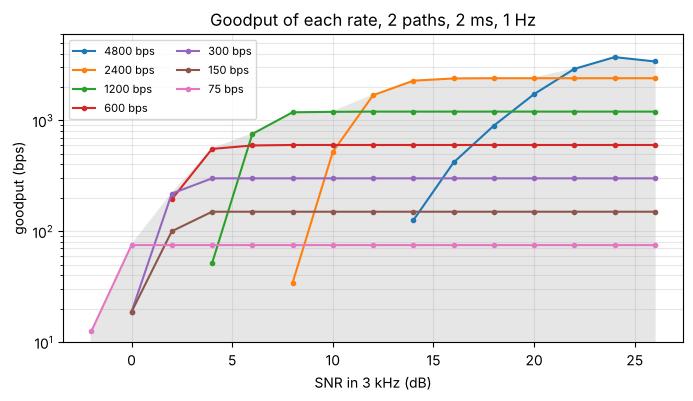

best rate by SNR: -2 dB: 75, 0 dB: 75, 2 dB: 300, 4 dB: 600, 6 dB: 1200, 8 dB: 1200, 10 dB: 1200, 12 dB: 2400, 14 dB: 2400, 16 dB: 2400, 18 dB: 2400, 20 dB: 2400, 22 dB: 4800, 24 dB: 4800, 26 dB: 4800


In [11]:
if points:
    fig, ax = plt.subplots(figsize=(8, 4))
    best = {}
    for rate in (4800, 2400, 1200, 600, 300, 150, 75):
        ps = sorted(select("rate", rate=rate), key=lambda p: p["snr_db"])
        if not ps:
            continue
        ps = [p for p in ps if p["frames_ok"] > 0]  # nothing delivered: off a log scale
        snr = [p["snr_db"] for p in ps]
        gp = [rate * delivered(p) for p in ps]
        ax.plot(snr, gp, "o-", markersize=3, label=f"{rate} bps")
        for s_, g_ in zip(snr, gp, strict=True):
            if g_ > best.get(s_, (0, None))[0]:
                best[s_] = (g_, rate)
    xs = sorted(best)
    ax.fill_between(xs, [best[x][0] for x in xs], color="0.9", zorder=0)
    ax.set_yscale("log")
    ax.set_ylim(10, 6000)
    ax.set_xlabel("SNR in 3 kHz (dB)")
    ax.set_ylabel("goodput (bps)")
    ax.set_title("Goodput of each rate, 2 paths, 2 ms, 1 Hz")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(ncol=2, fontsize=8)
    plt.show()
    print("best rate by SNR:", ", ".join(f"{x:g} dB: {best[x][1]}" for x in xs))

### Multipath: how long an echo can be

The equaliser measures the channel from the known probes: 16 symbols (6.7 ms) at 2400 bps,
20 symbols (8.3 ms) at 600 bps. So one might expect 2400 bps to give out at a shorter
delay spread than 600 bps. It does not: at a high SNR (25 dB, so noise is not the
problem), both are clean to 7-8 ms and both fail from 9 ms. The limit is this receiver's
own: its equaliser follows echoes up to 20 symbols (8.3 ms) after the first path
(`POSTCURSOR_TAPS` in `m110c/rx/equalize.py`), sized with margin over Table XVI's worst
case, 5 ms. It estimates the channel over many probes and known symbols, not one probe at
a time, so the probe's length is not the bound. A longer span would follow longer echoes,
at the cost of computation and of noise in more estimated taps.

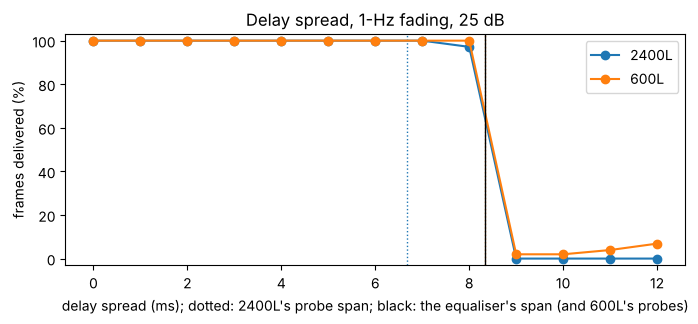

In [12]:
if points:
    fig, ax = plt.subplots()
    for rate, probe_ms in ((2400, 16 / 2.4), (600, 20 / 2.4)):
        ps = sorted(select("delay", rate=rate), key=lambda p: p["delay_ms"])
        (line,) = ax.plot(
            [p["delay_ms"] for p in ps], [100 * delivered(p) for p in ps], "o-", label=f"{rate}L"
        )
        ax.axvline(probe_ms, color=line.get_color(), ls=":", lw=1)
    ax.axvline(20 / 2.4, color="k", lw=1)
    ax.set_xlabel(
        "delay spread (ms); dotted: 2400L's probe span; black: the equaliser's span "
        "(and 600L's probes)"
    )
    ax.set_ylabel("frames delivered (%)")
    ax.set_ylim(-3, 103)
    ax.set_title("Delay spread, 1-Hz fading, 25 dB")
    ax.legend()
    plt.show()

### Fast fading: how often the channel is measured

2400 bps measures the channel once per 48 symbols (32 data + 16 probe); 600 bps once per
40, with probes half the frame; 75 bps has no probes, and decides each 32-symbol set on
its own. At 25 dB, as the fading speeds up: 2400 bps gives out between 5 and 7 Hz, while
600 and 75 bps hold to 15 Hz and fail by 20-30 Hz. Measuring the channel more often
triples the fading speed a mode can follow. Fast fading is what polar paths ("flutter")
bring, so they call for the slower rates even when the SNR is good.

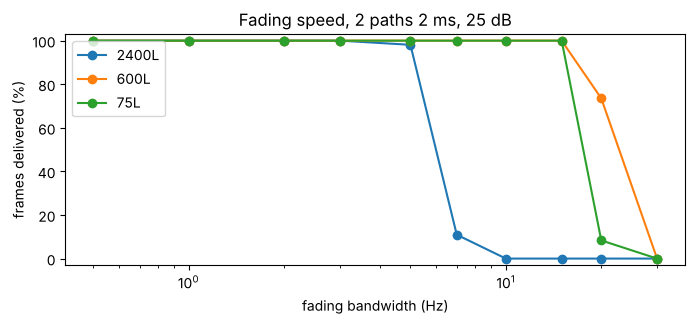

In [13]:
if points:
    fig, ax = plt.subplots()
    for rate in (2400, 600, 75):
        ps = sorted(select("doppler", rate=rate), key=lambda p: p["doppler_hz"])
        ax.plot(
            [p["doppler_hz"] for p in ps], [100 * delivered(p) for p in ps], "o-", label=f"{rate}L"
        )
    ax.set_xscale("log")
    ax.set_xlabel("fading bandwidth (Hz)")
    ax.set_ylabel("frames delivered (%)")
    ax.set_ylim(-3, 103)
    ax.set_title("Fading speed, 2 paths 2 ms, 25 dB")
    ax.legend()
    plt.show()

### So which mode?

What this sweep says, for this receiver:

| Conditions | Favours | Why (figure above) |
|---|---|---|
| very low SNR (0 dB and below) | 75 bps | the only rate that works there |
| moderate SNR (about 2-10 dB) | 300-1200 bps | the goodput crossovers |
| good SNR (about 12 dB up) | 2400 bps | the goodput crossovers |
| slow fading (fades of a second or more) | long interleave | short blocks miss whole fades |
| fast fading (5 Hz up, e.g. polar flutter) | 600 bps or slower | more frequent probing |
| echoes beyond about 8 ms | nothing, here | beyond this receiver's equaliser span |
| short messages, latency | short interleave, SNR allowing | 0.6-s block (playground) |

The SNR thresholds move with the channel (Table XVI tests each rate on a different one),
and with the receiver; the ordering is what carries over.